# SVM Sentiment Classification
Wersja z Pipeline i CV z oryginalnymi parametrami TF-IDF (stop_words=None, trigramy, C=0.3).

In [46]:
import pandas as pd
import numpy as np
import time

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix

import seaborn as sns
import matplotlib.pyplot as plt

In [47]:
import psutil
import os
import time

def print_resource_usage():
    # Pobieramy informacje o bieżącym procesie Pythona
    process = psutil.Process(os.getpid())
    
    # Zużycie pamięci RAM przez notatnik (w MB)
    mem_usage = process.memory_info().rss / (1024 * 1024) 
    
    # Ogólne obciążenie procesora (wszystkie rdzenie)
    cpu_usage = psutil.cpu_percent(interval=0.5) 
    
    print(f"\n[MONITOR ZASOBÓW]")
    print(f"Obciążenie CPU: {cpu_usage}%")
    print(f"Zużycie RAM przez model: {mem_usage:.2f} MB")
    print(f"--------------------------")

In [48]:
df = pd.read_csv('data/processed_reviews.csv')
print("Dataset balance:\n", df['label'].value_counts())

X = df['full_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Train: {len(X_train)}, Test: {len(X_test)}")

Dataset balance:
 label
1    29837
2    29837
0    29837
Name: count, dtype: int64
Train: 71608, Test: 17903


In [49]:
# Oryginalne parametry TF-IDF - empirycznie lepsze na tym datasecie
# stop_words=None: słowa łącznikowe i negacje ('not', 'no') niosą tu info o sentymencie
# ngram_range=(1,3): trigramy pomagają łapać frazy jak 'not good at all'
pipe = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=30000,
        stop_words=None,    # zachowujemy wszystkie słowa
        ngram_range=(1, 3), # unigramy + bigramy + trigramy
        lowercase=True,
        min_df=3
    )),
    ('svm', LinearSVC(
        C=1,
        max_iter=3000,
        dual='auto',
        random_state=42
    ))
])

In [50]:
# Walidacja krzyżowa - pipeline gwarantuje brak data leakage
print("Running 5-fold cross-validation...")
cv_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='f1_macro', n_jobs=-1)
print(f"CV F1 (macro): {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"Per-fold: {np.round(cv_scores, 4)}")

Running 5-fold cross-validation...
CV F1 (macro): 0.7473 ± 0.0018
Per-fold: [0.7474 0.7465 0.746  0.7507 0.746 ]


In [51]:
# Trening finalnego modelu na pełnym zbiorze treningowym
start_time = time.time()
pipe.fit(X_train, y_train)
print(f"Training completed in: {time.time() - start_time:.2f} seconds")

y_pred = pipe.predict(X_test)

print("\nSVM Classification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['Negative', 'Neutral', 'Positive']
))
print("Stan zasobów po treningu:")
print_resource_usage()

Training completed in: 26.27 seconds

SVM Classification Report:
              precision    recall  f1-score   support

    Negative       0.75      0.75      0.75      5967
     Neutral       0.67      0.66      0.66      5968
    Positive       0.83      0.85      0.84      5968

    accuracy                           0.75     17903
   macro avg       0.75      0.75      0.75     17903
weighted avg       0.75      0.75      0.75     17903

Stan zasobów po treningu:

[MONITOR ZASOBÓW]
Obciążenie CPU: 22.2%
Zużycie RAM przez model: 1322.22 MB
--------------------------


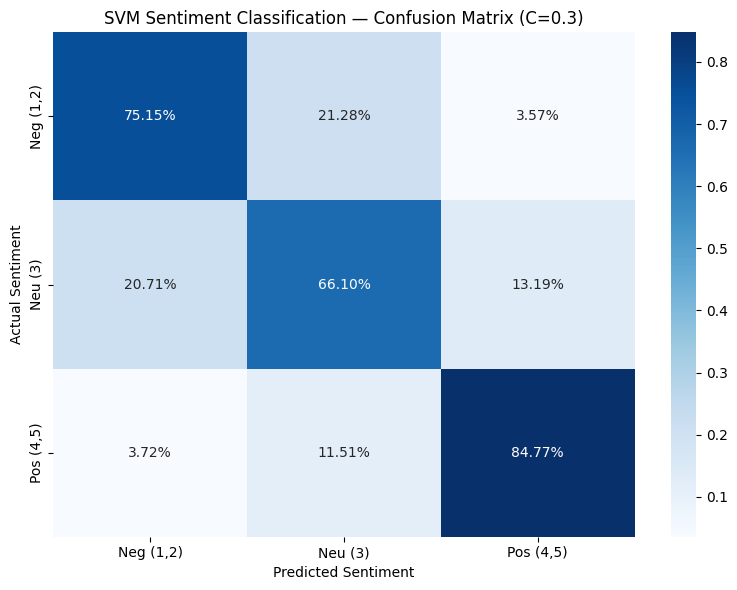

In [52]:
cm = confusion_matrix(y_test, y_pred)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_percent, annot=True, fmt='.2%', cmap='Blues',
    xticklabels=['Neg (1,2)', 'Neu (3)', 'Pos (4,5)'],
    yticklabels=['Neg (1,2)', 'Neu (3)', 'Pos (4,5)']
)
plt.ylabel('Actual Sentiment')
plt.xlabel('Predicted Sentiment')
plt.title('SVM Sentiment Classification — Confusion Matrix (C=0.3)')
plt.tight_layout()
plt.show()

In [56]:
# Tworzymy DataFrame z wynikami testowymi
results_df = pd.DataFrame({
    'text': X_test,
    'actual': y_test,
    'predicted': y_pred
})

# Wyciągamy błędy (np. model myślał, że to Neutral, a był Negatyw)
errors = results_df[results_df['actual'] != results_df['predicted']]

print(f"Liczba błędnych predykcji: {len(errors)}")

# Wyświetlmy 5 przykładów, gdzie model najbardziej przestrzelił
# (np. Recenzja Negatywna (0), którą model uznał za Pozytywną (2))
extreme_errors = errors[(errors['actual'] == 0) & (errors['predicted'] == 2)]

print("\nPrzykłady skrajnych pomyłek (Miał być Negatyw, jest Pozytyw):")
for i, row in extreme_errors.head(20).iterrows():
    print(f"--- TEXT: {row['text'][:200]}...") # pierwsze 200 znaków
    print(f"--- ACTUAL: {row['actual']} | PREDICTED: {row['predicted']}\n")

Liczba błędnych predykcji: 4415

Przykłady skrajnych pomyłek (Miał być Negatyw, jest Pozytyw):
--- TEXT: Serious health food If you're out for sheer health benefits without taste and without desirable texture, this one's for you.  I did not expect much out of it except health benefits, so I wasn't surpri...
--- ACTUAL: 0 | PREDICTED: 2

--- TEXT: frenchs horseradish mustard first of all I like Frenchs regular and deli mustards but when it comes to horseradish mustard they really havent got a clue there horseradish mustard sucks its not hot at ...
--- ACTUAL: 0 | PREDICTED: 2

--- TEXT: Stale cookies If you like stale cookies, you will love these expensive cookies from Tate.  My daughter sent me three packs for Father's Day.  She is a loving daughter and would not try to fool me into...
--- ACTUAL: 0 | PREDICTED: 2

--- TEXT: 192 creamers that must be  used in 3 MONTHS My creamers are coagulating and I have used only half.  I am DISAPPOINTED.  USE ANOTHER BRAND. 192 CREAMERS are TOO MUC

W razie czego szukalam czy nie dalam zlych parametrów a nie chcialam tego dawac do głównego kodu bo by liczył to 100 lat

In [ ]:
from sklearn.model_selection import GridSearchCV
import time

# 1. Poprawiona siatka parametrów dla LinearSVC
param_grid = {
    # Przetwarzanie tekstu (TF-IDF)
    'tfidf__max_features': [10000, 25000, None],
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [1, 2, 5],
    
    # Model (LinearSVC)
    'svm__C': [0.1, 1, 10],
    'svm__class_weight': [None, 'balanced'],
    'svm__dual': [False] 
}

# 2. Inicjalizacja GridSearchCV
grid_search = GridSearchCV(
    pipe, 
    param_grid, 
    cv=3, 
    scoring='f1_macro', 
    n_jobs=-1, 
    verbose=3 
)

print("Start Grid Search (LinearSVC)...")
start_time = time.time()
grid_search.fit(X_train, y_train)
duration = time.time() - start_time
print(f"Zakończono w: {duration:.2f} sekund")

# 3. Wyniki
print("\nNajlepsze parametry:", grid_search.best_params_)
print(f"Najlepszy wynik F1-macro: {grid_search.best_score_:.4f}")

# 4. Test
best_model = grid_search.best_estimator_
y_pred_grid = best_model.predict(X_test)

print("\n--- RAPORT KLASYFIKACJI ---")
print(classification_report(y_test, y_pred_grid))

🚀 Start Grid Search (LinearSVC)...
Fitting 3 folds for each of 108 candidates, totalling 324 fits


[CV 1/3] END svm__C=0.1, svm__class_weight=None, svm__dual=False, tfidf__max_features=10000, tfidf__min_df=1, tfidf__ngram_range=(1, 1);, score=0.735 total time=   7.2s
[CV 2/3] END svm__C=0.1, svm__class_weight=None, svm__dual=False, tfidf__max_features=10000, tfidf__min_df=1, tfidf__ngram_range=(1, 1);, score=0.737 total time=   7.5s
[CV 3/3] END svm__C=0.1, svm__class_weight=None, svm__dual=False, tfidf__max_features=10000, tfidf__min_df=1, tfidf__ngram_range=(1, 1);, score=0.737 total time=   7.5s
[CV 1/3] END svm__C=0.1, svm__class_weight=None, svm__dual=False, tfidf__max_features=10000, tfidf__min_df=2, tfidf__ngram_range=(1, 1);, score=0.735 total time=   7.5s
[CV 2/3] END svm__C=0.1, svm__class_weight=None, svm__dual=False, tfidf__max_features=10000, tfidf__min_df=2, tfidf__ngram_range=(1, 1);, score=0.737 total time=   7.6s
[CV 3/3] END svm__C=0.1, svm__class_weight=None, svm__dual=False, tfidf__max_features=10000, tfidf__min_df=2, tfidf__ngram_range=(1, 1);, score=0.737 total

/Users/kamilakapinos/dev/sentiment-analysis-magisterka/.venv/lib/python3.10/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV 2/3] END svm__C=0.1, svm__class_weight=balanced, svm__dual=False, tfidf__max_features=None, tfidf__min_df=1, tfidf__ngram_range=(1, 2);, score=0.759 total time=  30.2s
[CV 3/3] END svm__C=0.1, svm__class_weight=balanced, svm__dual=False, tfidf__max_features=None, tfidf__min_df=1, tfidf__ngram_range=(1, 2);, score=0.758 total time=  29.7s
[CV 3/3] END svm__C=0.1, svm__class_weight=balanced, svm__dual=False, tfidf__max_features=None, tfidf__min_df=5, tfidf__ngram_range=(1, 1);, score=0.737 total time=   7.9s
[CV 1/3] END svm__C=0.1, svm__class_weight=balanced, svm__dual=False, tfidf__max_features=None, tfidf__min_df=2, tfidf__ngram_range=(1, 2);, score=0.758 total time=  25.3s
[CV 2/3] END svm__C=0.1, svm__class_weight=balanced, svm__dual=False, tfidf__max_features=None, tfidf__min_df=2, tfidf__ngram_range=(1, 2);, score=0.760 total time=  23.9s
[CV 3/3] END svm__C=0.1, svm__class_weight=balanced, svm__dual=False, tfidf__max_features=None, tfidf__min_df=2, tfidf__ngram_range=(1, 2);,